How does the performance change for the top 10 models when the data is reduced by 25, 50 or 75%?

In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path
import os
from sklearn.metrics import balanced_accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import linregress

base_path = Path(r'Q:\Messdaten\EXPECTmine_data\02_MLinvitroTox_PosNeg\mlinvitrotox\data\input\invitro\pytcpl')
counts_aeids = pd.read_csv(r"Q:\Messdaten\EXPECTmine_data\02_MLinvitroTox_PosNeg\MLinvitroTox_PosNeg\data\processed\aeids_data_abundance.csv")
aeids = counts_aeids["aeid"]

og_dir = r"Q:\Messdaten\EXPECTmine_data\02_MLinvitroTox_PosNeg\mlinvitrotox\data\results\models"
root_dirs = ["final_models_retrained", "final_models_075", "final_models_050", "final_models_025"]

metrics_list = []

for root_dir in root_dirs:

    root_data_dir = os.path.join(og_dir, root_dir, "class")

    for aeid in aeids:

        base_path = os.path.join(
            root_data_dir,
            str(aeid),
        )

        pred_file = os.path.join(base_path, "FS_RandomForest", "mb_val_structure","test_predictions_default.csv")
        chem_file = os.path.join(base_path, "test_true_chemicals.csv")

        if not (os.path.isfile(pred_file) and os.path.isfile(chem_file)):
            continue

        preds = pd.read_csv(pred_file)
        chems = pd.read_csv(chem_file)

        # Merge safely (index-based only if you are 100% sure they align)
        df = chems.merge(preds, left_index=True, right_index=True)

        df["correct"] = (df["y_true"] == df["y_pred"]).astype(int)

        # Add identifiers
        df["aeid"] = aeid
        df["data"] = root_dir   # this is your 25%, 50%, etc.

        metrics_list.append(df)

# Final dataframe
metrics_df = pd.concat(metrics_list, ignore_index=True)

Bootstrapping

In [ ]:
# bootstrap metrics_df 1000 times to get a distribution of balanced accuracy scores for each aeid and data abundance

def bootstrap_predictions(metrics_df, n_boot=1000):

    bootstrap_results = []

    for aeid in metrics_df["aeid"].unique():

        aeid_df = metrics_df[
            metrics_df["aeid"] == aeid
        ].copy()

        # Make sure all models predict same compounds
        grouped = {
            abundance: df.reset_index(drop=True)
            for abundance, df in aeid_df.groupby("data")
        }

        n_samples = len(next(iter(grouped.values())))

        for b in range(n_boot):

            idx = np.random.choice(
                n_samples,
                size=n_samples,
                replace=True
            )

            for abundance, df in grouped.items():

                yt = df.loc[idx, "y_true"]
                yp = df.loc[idx, "y_pred"]

                bootstrap_results.append({
                    "aeid": aeid,
                    "data": abundance,
                    "bootstrap": b,
                    "balanced_accuracy": balanced_accuracy_score(
                        yt,
                        yp
                    )
                })

    return pd.DataFrame(bootstrap_results)


boot_df = bootstrap_predictions(
    metrics_df,
    n_boot=1000
)

In [ ]:
boot_melted = boot_df.melt(
    id_vars=["aeid", "data", "bootstrap"],
    value_vars=[
        "balanced_accuracy"
    ],
    var_name="metric",
    value_name="score"
)

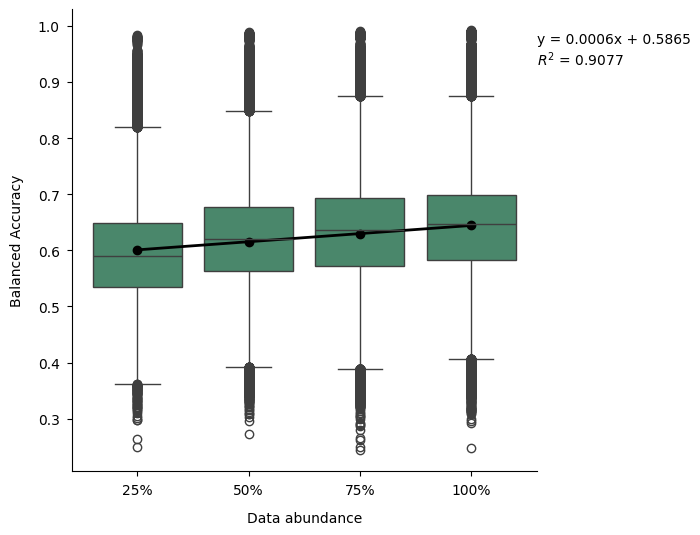

In [ ]:
# Plotting

label_map = {
    "final_models_025": "25%",
    "final_models_050": "50%",
    "final_models_075": "75%",
    "final_models_retrained": "100%"
}
data_order = ["final_models_025", "final_models_050", "final_models_075", "final_models_retrained"]

# Numeric x-values corresponding to abundance levels
x_numeric = np.array([25, 50, 75, 100])

metric = "balanced_accuracy"

# Keep only balanced accuracy
subset = boot_melted[
    boot_melted["metric"] == metric
]


fig, ax = plt.subplots(figsize=(6, 6))

# Boxplot (or violinplot, depending on your original figure)
sns.boxplot(
    data=subset,
    x="data",
    y="score",
    order=data_order,
    color="#40916c",
    ax=ax
)
sns.despine(ax=ax)

# Mean score per abundance level
means = (
    subset.groupby("data")["score"]
    .mean()
    .reindex(data_order)
)

y = means.values

# Linear regression
slope, intercept, r_value, p_value, std_err = linregress(
    x_numeric,
    y
)

# Predicted values
y_pred = slope * x_numeric + intercept

# Regression line
ax.plot(
    range(len(data_order)),
    y_pred,
    color="black",
    marker="o",
    linewidth=2,
    #label="Linear fit"
)

# Equation annotation
eq_text = (
    f"y = {slope:.4f}x + {intercept:.4f}\n"
    f"$R^2$ = {r_value**2:.4f}"
)

ax.text(
    1.0,
    0.95,
    eq_text,
    transform=ax.transAxes,
    fontsize=10,
    verticalalignment="top",
)

# Labels and title
ax.set_xticks(range(len(data_order)))
ax.set_xticklabels([label_map[x] for x in data_order])

ax.set_xlabel("Data abundance", labelpad=10)
ax.set_ylabel("Balanced Accuracy", labelpad=10)

ax.tick_params(axis="x", pad=5)
ax.tick_params(axis="y", pad=5)


#plt.savefig("figure_dataabundance.pdf", bbox_inches="tight")

plt.show()
